In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import discriminator as Discriminator
import generator as Generator
import feature_extractor as feature_extractor

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.util as util
import utils.visualization as vis


tf.keras.backend.set_image_data_format("channels_first")
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')


2024-04-20 15:13:01.984422: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-04-20 15:13:02.028625: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-20 15:13:02.028668: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-20 15:13:02.029912: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-20 15:13:02.038612: I tensorflow/core/platform/cpu_feature_guar

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA A100 80GB PCIe, compute capability 8.0


## Visualize data

In [2]:
# %matplotlib widget

# data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
#                                 batch_size=1, 
#                                 image_size=(192, 224, 192), 
#                                 channels_first=True,
#                                 shuffle=True, 
#                                 nb_patients=2, 
#                                 shuffle_before_selecting=False, 
#                                 server=False,
#                                 start_from=10)

# fc.imgshow_3D("", data_train[0][0][0,0])

### Validation visualization

In [3]:
def show_generated_image(id, G, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_gen_h4 = G(np.expand_dims(np.expand_dims(img_hunt3, axis=0), axis=0), training=False)
    img_gen_h4 = img_gen_h4[0,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)

    vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane)



### Loss functions

In [4]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = (real_loss + fake_loss)/2
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def feature_extractor_loss(Fe, h4_real, h4_fake):
    feat_h4_real_list = Fe(h4_real, training=True)
    feat_h4_fake_list = Fe(h4_fake, training=True)

    loss = tf.constant(0.0, dtype=tf.float16)
    for i in range(len(feat_h4_real_list)):
        loss += tf.reduce_mean(tf.abs(feat_h4_real_list[i] - feat_h4_fake_list[i]))
    loss /= len(feat_h4_real_list)
    return tf.cast(loss, tf.float32)

In [5]:
@tf.function
def train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        h4_fake = G(h3_batch, training=True)

        real_output = D(h4_batch, training=True)
        fake_output = D(h4_fake, training=True)

        _gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

        l1_loss = tf.reduce_mean(tf.abs(h4_batch - h4_fake))
        # percetual_loss = feature_extractor_loss(Fe, h4_batch, h4_fake)
        percetual_loss = 0.0
        gen_loss = _gen_loss + 25.0 * l1_loss + 0.25 * percetual_loss


        # scale loss
        gen_loss = g_optimizer.get_scaled_loss(gen_loss)
        disc_loss = d_optimizer.get_scaled_loss(disc_loss)

    gradients_of_generator = gen_tape.gradient(gen_loss, G.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, D.trainable_variables)

    gradients_of_generator = g_optimizer.get_unscaled_gradients(gradients_of_generator)
    gradients_of_discriminator = d_optimizer.get_unscaled_gradients(gradients_of_discriminator)

    g_optimizer.apply_gradients(zip(gradients_of_generator, G.trainable_variables))
    d_optimizer.apply_gradients(zip(gradients_of_discriminator, D.trainable_variables))

    return gen_loss, disc_loss, l1_loss, percetual_loss



In [6]:
# data_train = DataLoader(f"{pil.get_base_folder()}data/data_reduced/train", batch_size=1, image_size=(200, 240, 240), shuffle=True, channels_first=False)
# data = data_train[0]

# # dloader = DataLoader(root_folder=f"data_test", batch_size=3, image_size=(200, 240, 240))
# fc.imgshow_3D(f"Original", data[0][0,...,0], current_plane=150)

### Training

2024-04-20 15:13:06.373117: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79086 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:89:00.0, compute capability: 8.0



Epoch 1/50


2024-04-20 15:13:08.132913: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-20 15:13:08.218775: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-20 15:13:08.732184: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


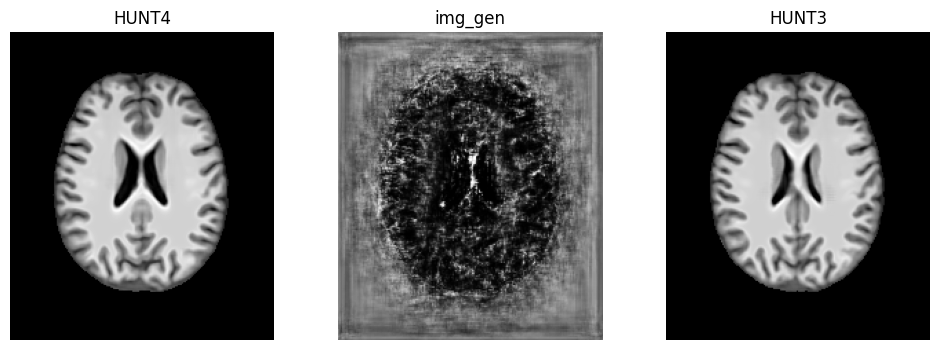

gen_loss: 144286.78203	disc_loss: 11913.02026	l1_loss: 0.40751	percetual_loss: 0.00000:   2%|▏         | 5/300 [01:23<37:58,  7.72s/it]  2024-04-20 15:14:47.989271: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f300d38fe40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-04-20 15:14:47.989302: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA A100 80GB PCIe, Compute Capability 8.0
2024-04-20 15:14:47.996087: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1713618888.076795 1529470 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
gen_loss: 8872.98627	disc_loss: 226.76337	l1_loss: 0.15815	percetual_loss: 0.00000: 100%|██████████| 300/300 [05:22<00:00,  1.08s/it]  



Epoch 2/50


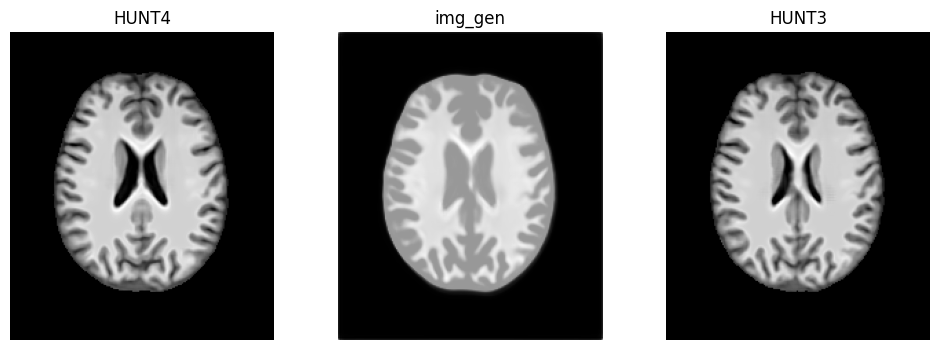

gen_loss: 1330.93475	disc_loss: 39.71254	l1_loss: 0.15702	percetual_loss: 0.00000:  16%|█▋        | 49/300 [00:38<03:19,  1.26it/s]

In [7]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    D = Discriminator.create_discriminator_model(input_shape)
    G = Generator.create_generator_model(input_shape)
    # Fe = feature_extractor.create_features_extractor((1,)+input_shape, pil.get_genesis_weights_path_name())
    Fe = None
    # Freeze features extractor layers
    # udl.freeze_layers(Fe, -1)

    # optimizers
    inital_lr = 1e-4
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)
    # g_optimizer = mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(inital_lr))
    # d_optimizer = mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(inital_lr))

    # ---- Data
    server = True
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=True,
                                    shuffle=True, 
                                    nb_patients=50, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 4
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)
    # tensorboard_callback = TensorBoard(log_dir=f"{current_path}/models/logs")

    log_dir=f"{current_path}/models/logs/"
    summary_writer = tf.summary.create_file_writer(
    log_dir + "fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    # %load_ext tensorboard
    # %tensorboard --logdir {log_dir}

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(g_optimizer=g_optimizer,
                                     d_optimizer=d_optimizer,
                                    G=G,
                                    D=D)
    # restore checkpoint
    # checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        show_generated_image("08202", G, input_shape, current_plane=current_plane)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
  
            gen_loss, disc_loss, l1_loss, percetual_loss = train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer)
            acum_loss_train.update((gen_loss, disc_loss, l1_loss, percetual_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['gen_loss', 'disc_loss', 'l1_loss', 'percetual_loss'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        if epoch > 44 and epoch % 22 == 0:
            inital_lr *= 0.5
            g_optimizer.learning_rate = inital_lr
            d_optimizer.learning_rate = inital_lr

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('gen_loss', loss_mean[0], step=epoch)
            tf.summary.scalar('disc_loss', loss_mean[1], step=epoch)
            tf.summary.scalar('l1_loss', loss_mean[2], step=epoch)
            tf.summary.scalar('percetual_loss', loss_mean[3], step=epoch)


train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]